#### **Introduction**

**Unsupervised learning** is an area of statistical learning that we use to infer trends to group cases based on similar attributes, naturally occurring trends, patterns, or relationships from unlabeled data. These models are often referred to as self-organising maps. A variety of methods are used as a strategy for dividing data into groups to carry out unsupervised learning, one of which is known as **clustering**. Clustering methods use data features to group observations into either distinct or overlapping sets.

#### __Clustering__
Clustering is the process of grouping similar data points together, such that data points in the same groups are more similar to other data points in that group than those in other groups.

The aim is to divide groups with similar characteristics and assign them to clusters. This will give us insights into the underlying patterns of the different groups/clusters. In this course, we will explore three types of clustering:

* **Hard Clustering**
* **Hierarchical Clustering**
* **Soft/Fuzzy Clustering**

Explanations are given in the image below.

<img src="https://raw.githubusercontent.com/Explore-AI/Pictures/master/sketch-clustering-types.png?raw=true" alt="Types of Clustering" style="width: 80%;"/>

#### __The K-means clustering algorithm__
K-means is an example of what is known as a **hard clustering** method, which means that the clusters, or groups that result, are distinct and non-overlapping. In other words, each observation will ultimately belong to only one cluster, although it may be passed around between clusters during the iterative training of the clustering model.

<img src="https://raw.githubusercontent.com/Explore-AI/Pictures/master/sketch-kmeans-clusters.png?raw=true" alt="Types of Clustering" style="width: 70%">

The main objective in K-means is to partition a dataset into K clusters. This is achieved by randomly initialising K cluster centroids (points to be used as the cluster centres), assigning each data point to the nearest centroid (according to some **distance measure**), and then updating the cluster centroids as well as data point membership at each iteration until the centroids stop changing.

One drawback of the K-means algorithm (and many other clustering algorithms) is that the analyst needs to specify the number of clusters, K. This is a difficult task because this number is seldom obvious for most real-world datasets. However, we do have methods available which we can use to determine the optimal number of clusters. We will cover some of these later on, but for now, let's take a look at the K-means algorithm, which, although it comes in many flavours, generally works as follows:

1. Pick the number of clusters K and randomly assign each observation a cluster number from 1 to K.
2. Repeat the following until cluster assignments stop changing:
    a. For each of the K clusters, compute the cluster centroid. The $k^{th}$ cluster centroid is the mean of the observations in the $k^{th}$ cluster.
    b. Assign each observation to the cluster whose centroid is closest (where closest is defined using a chosen distance metric such as **Euclidean distance**).

The sequence of images below illustrates the K-means algorithm as it iterates over a data set (these correspond to the algorithm above).

<img src="https://raw.githubusercontent.com/Explore-AI/Pictures/master/clustering_algorithm.png?raw=true" alt="Types of Clustering" style="width: 70%">

In [2]:
# data processing
import numpy as np
import pandas as pd
import datetime
from sklearn import preprocessing
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

# plotting
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:

import matplotlib.pyplot as plt
def style_plot(
    ax,
    title=None,
    xlabel=None,
    ylabel=None,
    title_fontsize=14,
    label_fontsize=11,
    remove_spines=True,
    grid=True,
    legend=True,
    xlim=None,
    ylim=None,
):
    """Apply a consistent style to a matplotlib Axes object."""
    if title:
        ax.set_title(
            title,
            fontsize=title_fontsize,
            fontweight="bold",
            pad=15)

    if xlabel:
        ax.set_xlabel(xlabel, fontsize=label_fontsize)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=label_fontsize)
    if grid:
        ax.grid(True, linestyle="--", alpha=0.4, linewidth=0.3, color="gray")
    if legend:
        ax.legend(fontsize=9)

    if remove_spines:
        for spine in ax.spines.values():
            spine.set_visible(False)

    ax.set_facecolor("whitesmoke")

    if xlim:
        ax.set_xlim(xlim)
    if ylim:
        ax.set_ylim(ylim)

    return ax


In [4]:
# Generate 8 blobs in 2D space
n_features = 2
centers = 8


X, y = make_blobs(
    n_samples=1000,
    centers=centers,
    n_features=n_features,
    random_state=68
)

# Create DataFrame
data = np.concatenate([X, y.reshape(-1, 1)], axis=1)

df = pd.DataFrame(
    data,
    columns=[
        *[f"feature_{i}" for i in range(n_features)],
        "y"
    ]
)

df["y"] = df["y"].astype(int)

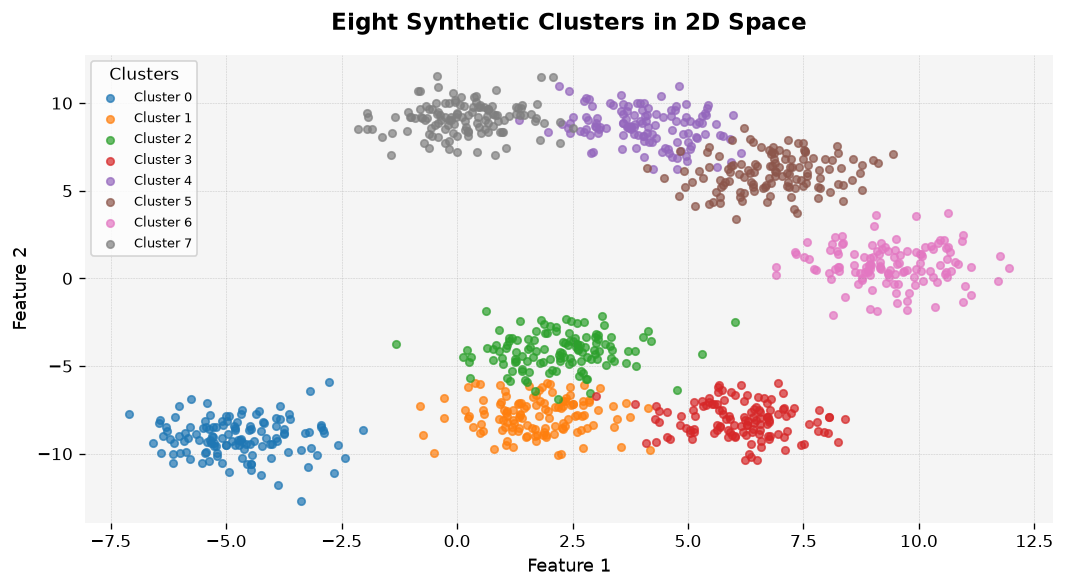

In [5]:
# Create figure and axes
fig, ax = plt.subplots(figsize=(9, 5), dpi=120)

# Plot each cluster
for center in range(centers):
    cluster = df[df["y"] == center]

    ax.scatter(
        cluster["feature_0"],
        cluster["feature_1"],
        s=20,
        alpha=0.7,
        label=f"Cluster {center}"
    )

# Apply consistent styling
style_plot(
    ax,
    title="Eight Synthetic Clusters in 2D Space",
    xlabel="Feature 1",
    ylabel="Feature 2"
)

ax.legend(title="Clusters", fontsize=8)
plt.tight_layout()
plt.show()

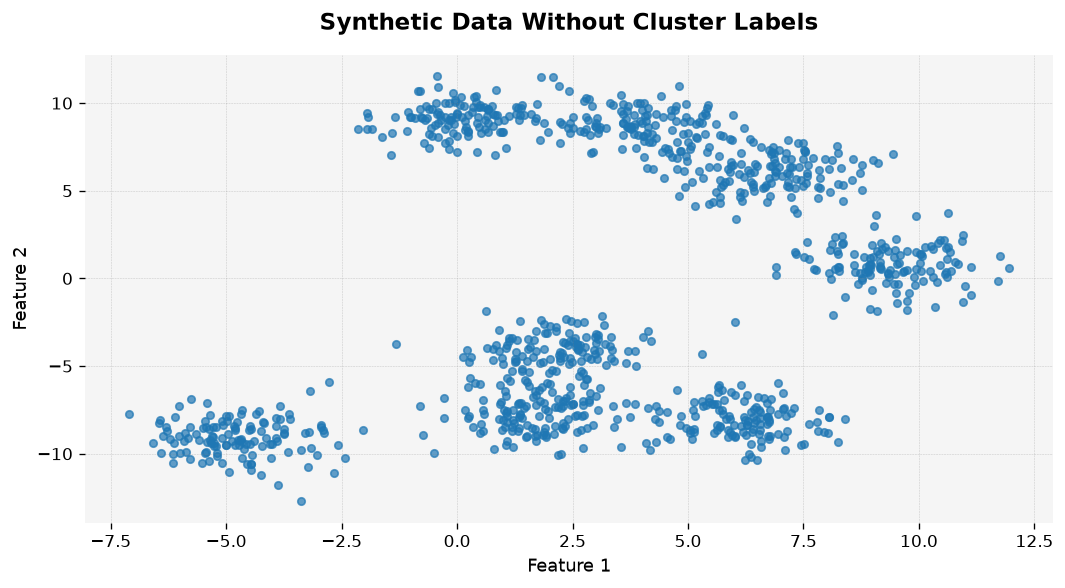

In [7]:
# Drop the cluster labels
df_no_labels = df.drop("y", axis=1)

# Create figure and axes
fig, ax = plt.subplots(figsize=(9, 5), dpi=120)

# Plot all observations
ax.scatter(
    df_no_labels["feature_0"],
    df_no_labels["feature_1"],
    s=20,
    alpha=0.7
)

# Apply consistent styling
style_plot(
    ax,
    title="Synthetic Data Without Cluster Labels",
    xlabel="Feature 1",
    ylabel="Feature 2",
    legend=False
)

plt.tight_layout()
plt.show()

__Interpretation:__ Unlike the previous plot, where colours identify the eight known clusters, this figure displays the same observations without their labels. The underlying cluster structure may still be visually apparent, but the individual cluster identities are no longer distinguishable.

This illustrates an important distinction in machine learning:

- Figure 1: Labelled data — the cluster membership (`y`) is available.
- Figure 2: Unlabelled data — only the feature values are available.

This unlabelled dataset is suitable for experimenting with unsupervised learning algorithms such as K-Means and DBSCAN.

#### __Preprocessing the data__

Since clustering algorithms rely on computing some form of distance metric, it is good practice to scale the data. If we don't do this, then we risk having features that contribute way more than others when deciding which cluster a given data point belongs to. For example, let's suppose we had a dataset with two features: `age` (ranging from `18` to `60`) and `income` (ranging from `10000` to `45000`). If we attempt to cluster without rescaling or normalising, then the `income` feature will always dominate the distance calculation to the extent that our results would be the same as if we didn't have the `age` feature in our dataset.

In [8]:
# create scaler object
scaler = StandardScaler()

# scale the data
X_scaled = scaler.fit_transform(df_no_labels)

#### **Deciding on K**

With clustering, we can't be too sure how many clusters we will get, and what information they will be clustered on! Looking at Figure 2 above, it seems that we have 4 or 5 distinct clusters. Let's pick $K=4$ for now.

In [12]:
k = 4

In [10]:
# Import KMeans model
from sklearn.cluster import KMeans
# Import time to measure algorithm runtime 
from time import time

In [14]:
km = KMeans(n_clusters=k, random_state=42)
km.fit(X_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",4
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](4, 2)","[

In [20]:
# Evaluating K-Means

y_pred = km.predict(X_scaled)
df_no_labels["cluster_label"] = y_pred
centers = scaler.inverse_transform(km.cluster_centers_)

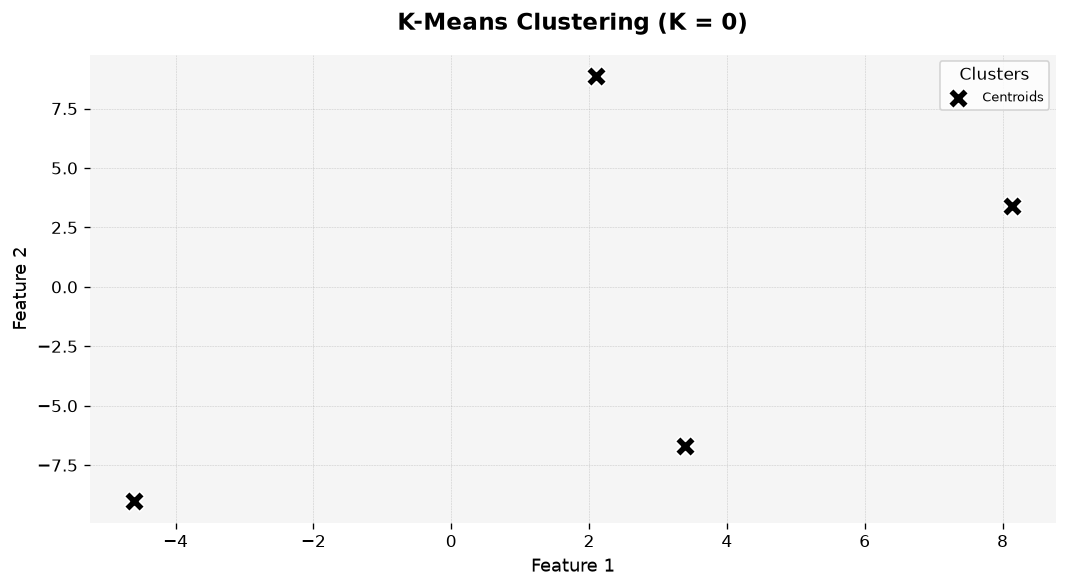

In [21]:
# Create figure and axes
fig, ax = plt.subplots(figsize=(9, 5), dpi=120)

# Plot observations by cluster
for k in range(k):
    cluster = df_no_labels[df_no_labels["cluster_label"] == k]

    ax.scatter(
        cluster["feature_0"],
        cluster["feature_1"],
        s=20,
        alpha=0.7,
        label=f"Cluster {k + 1}"
    )

# Plot cluster centroids
ax.scatter(
    centers[:, 0],
    centers[:, 1],
    s=150,
    marker="X",
    c="black",
    edgecolors="white",
    linewidths=1,
    label="Centroids",
    zorder=5
)

# Apply consistent styling
style_plot(
    ax,
    title=f"K-Means Clustering (K = {k})",
    xlabel="Feature 1",
    ylabel="Feature 2"
)

ax.legend(title="Clusters", fontsize=8)
plt.tight_layout()
plt.show()

#### **Evaluation metrics**

Clustering algorithms like K-means produce clusters, but how do we know if these clusters are of good quality?
We can use evaluation metrics to **assess the quality** of our clusters. Two common metrics are the `silhouette score` and the `Davies-Bouldin index`.

#### __Silhouette Score__
The silhouette score is a measure of how similar an object is to its own cluster (cohesion) compared to other clusters (separation).
It ranges from -1 to 1, where a high value indicates that the object is well-matched to its own cluster and poorly matched to neighbouring clusters.
A silhouette score close to 1 suggests that the object is appropriately assigned to its cluster, while a score near -1 indicates that it is assigned to the wrong cluster.
In clustering, we aim for a high silhouette score, as it indicates well-separated clusters and a clear distinction between them.
The silhouette score is computed for each sample and then averaged to obtain an overall score for the clustering.

In [22]:
from sklearn.metrics import silhouette_score

In [25]:

# Calculate silhouette score
score = silhouette_score(X_scaled, km.labels_)
print(f"Silhouette Score: {score:.4f}")

Silhouette Score: 0.5815


__Insight:__

> The silhouette score of 0.5815 indicates a reasonably good clustering result. It suggests that the clusters are fairly distinct and well-defined, with minimal overlap between them. Overall, it indicates a relatively successful partitioning of the data into meaningful clusters.

---

#### __Interpretation__

The Silhouette Score ranges from -1 to +1.

| Score       | Interpretation                                               |
| ----------- | ------------------------------------------------------------ |
| Close to +1 | Well-separated, compact clusters                             |
| Around 0    | Clusters overlap or observations lie near cluster boundaries |
| Close to -1 | Many observations may be assigned to the wrong clusters      |

Important: A higher Silhouette Score generally indicates better-defined clusters. You can calculate it for different values of K (for example, K = 2 to 10) to help determine a suitable number of clusters.

---

#### __Davies-Bouldin Index__
The Davies-Bouldin index is another measure of cluster validity that evaluates the average similarity between each cluster and its most similar cluster.
It is defined as the ratio of the average intra-cluster distance to the distance between cluster centroids.
Lower values of the Davies-Bouldin index indicate better clustering, with tight and well-separated clusters.
A high Davies-Bouldin index suggests that clusters overlap or are poorly separated.
Like the silhouette score, the Davies-Bouldin index is used to assess the quality of clustering solutions and guide the selection of the optimal number of clusters.

Let's calculate the Davies-Bouldin index for our clusters.

In [26]:
from sklearn.metrics import davies_bouldin_score

In [27]:
# Calculate Davies-Bouldin Index
db_index = davies_bouldin_score(X_scaled, km.labels_)
print(f"Davies-Bouldin Index: {db_index:.4f}")

Davies-Bouldin Index: 0.5674


**Interpretation**

The Davies-Bouldin Index evaluates clustering quality by comparing:
- Within-cluster dispersion: How spread out observations are within each cluster.
- Between-cluster separation: How far apart the clusters are from one another.

The Davies-Bouldin Index of $0.5674$ suggests that the four clusters produced by K-Means are reasonably compact and well separated.

This indicates that:
- Observations within individual clusters have relatively low dispersion.
- The clusters are reasonably distinct from one another.
- There is a favourable balance between within-cluster similarity and between-cluster separation.

__Conclusion:__

The Davies-Bouldin Index of $0.5674$ indicates reasonably good clustering performance. The relatively low value suggests that K-Means has produced clusters with good internal compactness and separation. However, this metric should be considered alongside the Silhouette Score when evaluating the quality of the clustering solution.

Note: The Davies-Bouldin Index has no universal threshold for good clustering. Its interpretation is most useful when comparing different values of K on the same dataset.

#### **Advantages and disadvantages of k-means clustering**

**Advantages**
- Computationally efficient clustering technique
- Suitable for large datasets
- Easy to implement and interpret
- Easily adaptable to new datasets

**Disadvantages**
- Lacks consistency
- Sensitive to scaling
- Dependent on initial values